# CIE 2 – Activity 2: Simple House Price Prediction

**Course:** Machine Learning (ADPC509)  
**Department:** Artificial Intelligence and Data Science  
**Class:** T.Y. B.Tech  
**Semester:** V  
**Academic Year:** 2026–27

**Student Name:** [Your Name]  
**Roll Number:** [Your Roll Number]  
**Division:** [Your Division]

## Objective

To build a Linear Regression model for predicting house prices using property features and evaluate its performance using suitable regression metrics.

## Dataset

California Housing Dataset

## Tools Used

- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Scikit-learn

**Dataset Source:** Scikit-learn California Housing Dataset

**Source Link:** https://scikit-learn.org/stable/datasets/real_world.html#california-housing-dataset

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing

# Load the California Housing dataset
housing = fetch_california_housing(as_frame=True)

# Convert the dataset into a DataFrame
df = housing.frame

# Display the first five rows
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## Step 1: Dataset Selection and Understanding

The California Housing dataset contains information about housing districts in California, USA. It includes numerical features such as median income, house age and average rooms.

The target variable is the median house value, which is continuous and numerical. The dataset is suitable for predicting house prices using Linear Regression.

In [2]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns)
print("\nMissing values:")
print(df.isnull().sum())
print("\nData types:")
print(df.dtypes)

Dataset shape: (20640, 9)

Column names:
Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Data types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object


## Step 2: Dataset Inspection
The dataset contains 20,640 rows and 9 columns. It has 8 input features and 1 target column, MedHouseVal. The missing-value check helps confirm whether any data needs to be handled before training.

In [3]:
X = df[["MedInc"]]
y = df["MedHouseVal"]

print("Input feature:", X.columns[0])
print("Target variable:", y.name)

Input feature: MedInc
Target variable: MedHouseVal


## Step 3: Select Input and Target
MedInc (median income) is the input feature used to predict MedHouseVal (median house value). Since the target is a continuous numerical value, this is a regression problem.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 16512
Testing samples: 4128


## Step 4: Train-Test Split
The dataset is split into 80% training data and 20% testing data. The model learns from the training data, then its performance is checked using the unseen testing data. The random_state value makes the split reproducible.

In [5]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Model training completed.")
print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

Model training completed.
Coefficient: 0.4193384939381271
Intercept: 0.4445972916907879


## Step 5: Model Training
Linear Regression learns the relationship between median income and median house value from the training data. The coefficient shows how the predicted value changes with income, while the intercept is the model's predicted value when income is zero.

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R² score:", r2)

MAE: 0.629908653009376
MSE: 0.7091157771765549
RMSE: 0.8420901241414455
R² score: 0.45885918903846656


## Step 6: Model Evaluation
The model predicts house values for the testing data. MAE and RMSE measure the average prediction error, while MSE gives greater weight to larger errors. R² indicates how much of the variation in house values is explained by the model. Lower error values and an R² closer to 1 indicate better performance.

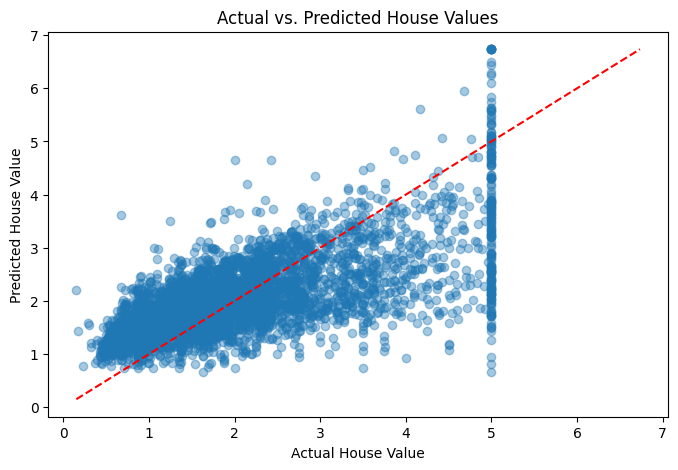

In [7]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.4)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], "r--")

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs. Predicted House Values")
plt.show()

## Step 7: Actual vs. Predicted Plot
The scatter plot compares actual house values with the model's predictions. Points closer to the red dashed line represent more accurate predictions. The plot helps visualize the model's performance.

In [8]:
new_income = pd.DataFrame({"MedInc": [5.0]})
predicted_value = model.predict(new_income)[0]

print("Median income:", new_income["MedInc"][0])
print("Predicted house value (in $100,000s):", predicted_value)
print("Approximate predicted value in dollars:", predicted_value * 100000)

Median income: 5.0
Predicted house value (in $100,000s): 2.5412897613814236
Approximate predicted value in dollars: 254128.97613814235


## Step 8: Prediction for New Input
The trained model predicts the median house value for a new input where median income is 5.0. The prediction is shown in the dataset's original unit and converted to dollars for easier interpretation.

## Conclusion
A Linear Regression model was trained using median income to predict median house value. Its performance was evaluated using MAE, MSE, RMSE, and R² score. The actual-versus-predicted plot helped visualize the predictions, and the trained model was used to estimate a value for a new income input.